In [1]:
import os
import re
import colorsys
import numpy as np
import pandas as pd
import matplotlib.colors as mcolors
from scipy.stats import gaussian_kde

base_dir = '.'
run_names = ['aiden-pbe-l0', 'aiden-pbe-l1', 'aiden-pbe-l2', 'aiden-pbe-l3', 'aiden-pbe-l4']
train_colors = ['#e5ab01', '#a885ca', '#5799c6', '#69884a', '#d85f01']
labels = [r'$\ell=0$', r'$\ell=1$', r'$\ell=2$', r'$\ell=3$', r'$\ell=4$']
bar_train_color = '#43978F'
bar_val_color = '#F6C957'

csv_path = os.path.join(base_dir, 'mp_train_val_lmax_nmae.csv')
charge_csv_path = os.path.join(base_dir, 'mp_train_val_lmax_charge_5000.csv')

FLOAT = r'(?:[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?|[-+]?inf|nan)'
resume_pattern = re.compile(r'Full resume at step=(\d+)', re.IGNORECASE)
train_pattern = re.compile(rf'Step\s+(\d+)\s+\|.*?epoch=\d+.*?train_mae=({FLOAT})\s+train_nmae=({FLOAT})', re.IGNORECASE)
val_pattern = re.compile(rf'Step\s+(\d+)\s+\|\s*train_mae=({FLOAT})\s+train_nmae=({FLOAT})\s+\|\s+val_mae=({FLOAT})\s+val_nmae=({FLOAT})', re.IGNORECASE)

def desaturate(color, saturation_scale=0.42):
    rgb = mcolors.to_rgb(color)
    h, s, v = colorsys.rgb_to_hsv(*rgb)
    return colorsys.hsv_to_rgb(h, s * saturation_scale, v)

def valid_value(value):
    return np.isfinite(value) and value > 0.0

def parse_log(log_path):
    train_records = {}
    val_records = {}

    with open(log_path, 'r', encoding='utf-8', errors='ignore') as f:
        for line in f:
            resume_match = resume_pattern.search(line)
            if resume_match is not None:
                resume_step = int(resume_match.group(1))
                train_records = {step: value for step, value in train_records.items() if step <= resume_step}
                val_records = {step: value for step, value in val_records.items() if step <= resume_step}
                continue

            train_match = train_pattern.search(line)
            if train_match is not None:
                step = int(train_match.group(1))
                train_nmae = float(train_match.group(3))
                if step > 0 and valid_value(train_nmae):
                    train_records[step] = train_nmae
                continue

            val_match = val_pattern.search(line)
            if val_match is not None:
                step = int(val_match.group(1))
                train_nmae = float(val_match.group(3))
                val_nmae = float(val_match.group(5))
                if step > 0 and valid_value(train_nmae) and valid_value(val_nmae):
                    val_records[step] = (train_nmae, val_nmae)

    train_steps = np.array(sorted(train_records.keys()), dtype=float)
    train_nmae = np.array([train_records[int(step)] for step in train_steps], dtype=float)
    val_steps = np.array(sorted(val_records.keys()), dtype=float)
    val_train_nmae = np.array([val_records[int(step)][0] for step in val_steps], dtype=float)
    val_nmae = np.array([val_records[int(step)][1] for step in val_steps], dtype=float)

    if len(train_steps) == 0:
        raise RuntimeError(f'No valid training NMAE found in: {log_path}')
    if len(val_steps) == 0:
        raise RuntimeError(f'No valid validation NMAE found in: {log_path}')

    best_idx = np.argmin(val_nmae)
    best_step = val_steps[best_idx]
    best_train_nmae = val_train_nmae[best_idx]
    best_val_nmae = val_nmae[best_idx]

    return {
        'train_steps': train_steps,
        'train_nmae': train_nmae * 100.0,
        'val_steps': val_steps,
        'val_nmae': val_nmae * 100.0,
        'best_step': best_step,
        'best_train_nmae': best_train_nmae * 100.0,
        'best_val_nmae': best_val_nmae * 100.0,
    }

if not os.path.isfile(csv_path):
    raise FileNotFoundError(f'Cannot find CSV file: {csv_path}')
if not os.path.isfile(charge_csv_path):
    raise FileNotFoundError(f'Cannot find CSV file: {charge_csv_path}')

loss_data = {}

for run_name in run_names:
    log_path = os.path.join(base_dir, run_name, 'train.log')
    if not os.path.isfile(log_path):
        raise FileNotFoundError(f'Cannot find log file: {log_path}')

    loss_data[run_name] = parse_log(log_path)

    d = loss_data[run_name]
    print(
        f'{run_name:12s} | '
        f'train NMAE = {d["best_train_nmae"]:.6f}% | '
        f'val NMAE = {d["best_val_nmae"]:.6f}% | '
        f'step = {int(d["best_step"])}'
    )

df = pd.read_csv(csv_path, sep=None, engine='python')
df['split'] = df['split'].astype(str).str.strip().str.lower()
train_df = df[df['split'] == 'train'].copy()
val_df = df[df['split'] == 'val'].copy()

distribution_data = {}

for i in range(len(labels)):
    column = f'l{i}_nmae'

    train_values = pd.to_numeric(train_df[column], errors='coerce').to_numpy(dtype=float)
    val_values = pd.to_numeric(val_df[column], errors='coerce').to_numpy(dtype=float)

    train_values = train_values[np.isfinite(train_values) & (train_values >= 0.0)] * 100.0
    val_values = val_values[np.isfinite(val_values) & (val_values >= 0.0)] * 100.0

    if len(train_values) < 2 or len(val_values) < 2:
        raise RuntimeError(f'Not enough samples for {column}')

    distribution_data[i] = {
        'train': train_values,
        'val': val_values,
    }

charge_df = pd.read_csv(charge_csv_path, sep=None, engine='python')
true_charge = pd.to_numeric(charge_df['true_charge_e'], errors='coerce').to_numpy(dtype=float)

charge_data = {}

for i in range(len(labels)):
    pred_charge = pd.to_numeric(charge_df[f'l{i}_charge_e'], errors='coerce').to_numpy(dtype=float)
    mask = np.isfinite(true_charge) & np.isfinite(pred_charge)

    charge_data[i] = {
        'true': true_charge[mask],
        'pred': pred_charge[mask],
    }

all_charge_values = [true_charge[np.isfinite(true_charge)]]

for i in range(len(labels)):
    pred = charge_data[i]['pred']
    if len(pred) > 0:
        all_charge_values.append(pred)

all_charge_values = np.concatenate(all_charge_values)
charge_min = all_charge_values.min()
charge_max = all_charge_values.max()
charge_pad = 0.02 * (charge_max - charge_min) if charge_max > charge_min else 1.0
charge_lo = charge_min - charge_pad
charge_hi = charge_max + charge_pad

print('Data preprocessing complete.')


aiden-pbe-l0   | train NMAE = 1.348891% | val NMAE = 1.269456% | step = 1865000
aiden-pbe-l1   | train NMAE = 1.095188% | val NMAE = 1.019159% | step = 1958000
aiden-pbe-l2   | train NMAE = 0.804703% | val NMAE = 0.766351% | step = 1970000
aiden-pbe-l3   | train NMAE = 0.637805% | val NMAE = 0.621438% | step = 1903000
aiden-pbe-l4   | train NMAE = 0.444986% | val NMAE = 0.454244% | step = 1947000
Data preprocessing complete.


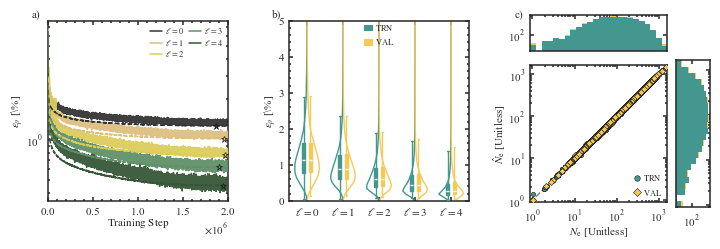

In [13]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde

FTSZ=8
LABELSZ=8
TICKSZ=8
LEGENDSZ=6
PANEL_FTSZ=8

mpl.rcParams['font.family']='sans-serif'
mpl.rcParams['font.sans-serif']=['Times New Roman']
mpl.rcParams['mathtext.fontset']='stix'
mpl.rcParams['font.size']=FTSZ
mpl.rcParams['axes.labelsize']=LABELSZ
mpl.rcParams['xtick.labelsize']=TICKSZ
mpl.rcParams['ytick.labelsize']=TICKSZ
mpl.rcParams['legend.fontsize']=LEGENDSZ
mpl.rcParams['axes.linewidth']=1.1
mpl.rcParams['lines.linewidth']=1.1
mpl.rcParams['xtick.major.width']=1.1
mpl.rcParams['ytick.major.width']=1.1
mpl.rcParams['xtick.minor.width']=1.1
mpl.rcParams['ytick.minor.width']=1.1
mpl.rcParams['xtick.major.size']=3.0
mpl.rcParams['ytick.major.size']=3.0
mpl.rcParams['xtick.minor.size']=1.5
mpl.rcParams['ytick.minor.size']=1.5
mpl.rcParams['xtick.direction']='in'
mpl.rcParams['ytick.direction']='in'
mpl.rcParams['figure.dpi']=100
mpl.rcParams['text.usetex']=False

train_colors=['#343434','#DEBF80','#DCCD5B','#5F9069','#375637']
labels=[r'$\ell=0$',r'$\ell=1$',r'$\ell=2$',r'$\ell=3$',r'$\ell=4$']
dist_train_color='#43978F'
dist_val_color='#F6C957'
charge_train_color='#43978F'
charge_val_color='#F6C957'

def draw_half_violin_outline(ax,data,center,side,color,half_width=0.34,lw=1.0):
    data=np.asarray(data,dtype=float)
    data=data[np.isfinite(data)]
    if len(data)<2:
        return
    dmin=max(0.0,data.min())
    dmax=data.max()
    if dmax<=dmin:
        ax.plot([center,center],[dmin,dmax+1e-6],color=color,lw=lw,zorder=2)
        return
    pad=0.08*(dmax-dmin)
    y=np.linspace(max(0.0,dmin-pad),dmax+pad,256)
    kde=gaussian_kde(data)
    density=kde(y)
    if np.allclose(density.max(),0.0):
        return
    density=density/density.max()*half_width
    x=center-density if side=='left' else center+density
    ax.plot(x,y,color=color,lw=lw,zorder=2)

plt.close('all')
fig=plt.figure(figsize=(7.2,2.6))
gs=fig.add_gridspec(1,3,left=0.065,right=0.985,bottom=0.18,top=0.92,wspace=0.34)

ax_loss=fig.add_subplot(gs[0,0])
ax_bar=fig.add_subplot(gs[0,1])
gs_c=gs[0,2].subgridspec(2,2,width_ratios=[4,1],height_ratios=[1,4],wspace=0.10,hspace=0.10)
ax_histx=fig.add_subplot(gs_c[0,0])
ax_charge=fig.add_subplot(gs_c[1,0])
ax_histy=fig.add_subplot(gs_c[1,1],sharey=ax_charge)

for a in [ax_loss,ax_bar,ax_charge,ax_histx,ax_histy]:
    a.tick_params(axis='both',which='major',direction='in',top=True,right=True,width=1.1,length=3.0)
    a.tick_params(axis='both',which='minor',direction='in',top=True,right=True,width=1.1,length=1.5)
    for spine in a.spines.values():
        spine.set_linewidth(1.1)

ax_loss.set_box_aspect(1)
ax_bar.set_box_aspect(1)
ax_charge.set_box_aspect(1)

for i,(run_name,color) in enumerate(zip(run_names,train_colors)):
    d=loss_data[run_name]
    ax_loss.plot(d['train_steps'],d['train_nmae'],color=color,linestyle='-',lw=1.1,alpha=0.95,zorder=2+i)

for i,(run_name,color) in enumerate(zip(run_names,train_colors)):
    d=loss_data[run_name]
    ax_loss.plot(d['val_steps'],d['val_nmae'],color=color,linestyle='--',lw=1.1,alpha=1.0,zorder=20+i)

for i,(run_name,color) in enumerate(zip(run_names,train_colors)):
    d=loss_data[run_name]
    ax_loss.plot(d['best_step'],d['best_val_nmae'],marker='*',linestyle='None',markersize=5.0,markerfacecolor=color,markeredgecolor='k',markeredgewidth=0.5,zorder=40+i,clip_on=False)

ax_loss.set_yscale('log')
ax_loss.set_xlim(0,2e6)
ax_loss.set_xlabel(r'$\mathrm{Training\ Step}$')
ax_loss.set_ylabel(r'$\varepsilon_{\rho}$ [\%]')
ax_loss.xaxis.set_minor_locator(mticker.AutoMinorLocator(5))
ax_loss.yaxis.set_minor_locator(mticker.LogLocator(base=10.0,subs=np.arange(2,10)*0.1))
ax_loss.yaxis.set_minor_formatter(mticker.NullFormatter())
ax_loss.ticklabel_format(style='sci',axis='x',scilimits=(6,6),useMathText=True)
ax_loss.xaxis.get_offset_text().set_fontsize(TICKSZ)

model_handles=[Line2D([0],[0],color=color,lw=1.1,linestyle='-',label=label) for color,label in zip(train_colors,labels)]
ax_loss.legend(handles=model_handles,loc='upper right',ncol=2,frameon=False,fontsize=LEGENDSZ,handlelength=1.4,handletextpad=0.35,columnspacing=0.65,labelspacing=0.20,borderaxespad=0.20)

x=np.arange(len(labels))
violin_half_width=0.34
box_offset=0.095
box_width=0.10

for i in range(len(labels)):
    train_values=distribution_data[i]['train']
    val_values=distribution_data[i]['val']
    draw_half_violin_outline(ax_bar,train_values,x[i],'left',dist_train_color,half_width=violin_half_width,lw=1.0)
    draw_half_violin_outline(ax_bar,val_values,x[i],'right',dist_val_color,half_width=violin_half_width,lw=1.0)
    ax_bar.boxplot(train_values,positions=[x[i]-box_offset],widths=box_width,patch_artist=True,showfliers=False,manage_ticks=False,zorder=4,whis=[0,95],boxprops=dict(facecolor=dist_train_color,edgecolor=dist_train_color,linewidth=1.0),whiskerprops=dict(color=dist_train_color,linewidth=1.0),capprops=dict(color=dist_train_color,linewidth=1.0),medianprops=dict(color='#FFFFFF',linewidth=1.0))
    ax_bar.boxplot(val_values,positions=[x[i]+box_offset],widths=box_width,patch_artist=True,showfliers=False,manage_ticks=False,zorder=4,whis=[0,95],boxprops=dict(facecolor=dist_val_color,edgecolor=dist_val_color,linewidth=1.0),whiskerprops=dict(color=dist_val_color,linewidth=1.0),capprops=dict(color=dist_val_color,linewidth=1.0),medianprops=dict(color='#FFFFFF',linewidth=1.0))

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(labels)
ax_bar.set_xlim(-0.50,len(labels)-0.50)
ax_bar.set_ylim(0,5)
ax_bar.set_ylabel(r'$\varepsilon_{\rho}$ [\%]')
ax_bar.xaxis.set_minor_locator(mticker.NullLocator())
ax_bar.yaxis.set_minor_locator(mticker.AutoMinorLocator(5))

distribution_handles=[Patch(facecolor=dist_train_color,edgecolor=dist_train_color,linewidth=0.8,label=r'$\mathrm{TRN}$'),Patch(facecolor=dist_val_color,edgecolor=dist_val_color,linewidth=0.8,label=r'$\mathrm{VAL}$')]
ax_bar.legend(handles=distribution_handles,loc='upper center',bbox_to_anchor=(0.50,1.01),ncol=1,frameon=False,fontsize=LEGENDSZ,handlelength=1.0,handletextpad=0.35,columnspacing=0.7,borderaxespad=0.0)

split_series=charge_df['split'].astype(str).str.strip().str.lower()
pred_col='l4_charge_e'
train_mask=split_series=='train'
val_mask=split_series=='val'

true_train=pd.to_numeric(charge_df.loc[train_mask,'true_charge_e'],errors='coerce').to_numpy(dtype=float)
pred_train=pd.to_numeric(charge_df.loc[train_mask,pred_col],errors='coerce').to_numpy(dtype=float)
true_val=pd.to_numeric(charge_df.loc[val_mask,'true_charge_e'],errors='coerce').to_numpy(dtype=float)
pred_val=pd.to_numeric(charge_df.loc[val_mask,pred_col],errors='coerce').to_numpy(dtype=float)

mask_train=np.isfinite(true_train)&np.isfinite(pred_train)&(true_train>0)&(pred_train>0)
mask_val=np.isfinite(true_val)&np.isfinite(pred_val)&(true_val>0)&(pred_val>0)

true_train=true_train[mask_train]
pred_train=pred_train[mask_train]
true_val=true_val[mask_val]
pred_val=pred_val[mask_val]

all_charge=np.concatenate([true_train,pred_train,true_val,pred_val])
charge_lo=all_charge.min()/1.08
charge_hi=all_charge.max()*1.08
charge_bins=np.logspace(np.log10(charge_lo),np.log10(charge_hi),25)

ax_charge.plot([charge_lo,charge_hi],[charge_lo,charge_hi],'--',lw=1.1,color='#888888',zorder=1)
band_x=np.logspace(np.log10(charge_lo),np.log10(charge_hi),400)
ax_charge.fill_between(band_x,band_x*0.995,band_x*1.005,color='#DEDEDE',linewidth=0,zorder=0)

ax_charge.scatter(true_train,pred_train,s=10,marker='o',facecolors=charge_train_color,edgecolors='k',linewidths=0.4,alpha=1.0,zorder=3)
ax_charge.scatter(true_val,pred_val,s=10,marker='D',facecolors=charge_val_color,edgecolors='k',linewidths=0.4,alpha=1.0,zorder=4)

ax_charge.set_xscale('log')
ax_charge.set_yscale('log')
ax_charge.set_xlim(charge_lo,charge_hi)
ax_charge.set_ylim(charge_lo,charge_hi)
ax_charge.set_xlabel(r'$N_{\rm e}$ [Unitless]')
ax_charge.set_ylabel(r'$\hat{N}_{\rm e}$ [Unitless]')
ax_charge.xaxis.set_minor_locator(mticker.LogLocator(base=10.0,subs=np.arange(2,10)*0.1))
ax_charge.yaxis.set_minor_locator(mticker.LogLocator(base=10.0,subs=np.arange(2,10)*0.1))
ax_charge.xaxis.set_minor_formatter(mticker.NullFormatter())
ax_charge.yaxis.set_minor_formatter(mticker.NullFormatter())

ax_histx.hist([true_train,true_val],bins=charge_bins,stacked=True,color=[charge_train_color,charge_val_color],edgecolor='none',linewidth=0)
ax_histx.set_xscale('log')
ax_histx.set_yscale('log')
ax_histx.set_xlim(charge_lo,charge_hi)
ax_histx.set_ylim(bottom=0.8)
ax_histx.xaxis.set_minor_locator(mticker.LogLocator(base=10.0,subs=np.arange(2,10)*0.1))
ax_histx.xaxis.set_minor_formatter(mticker.NullFormatter())
ax_histx.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax_histx.yaxis.set_minor_locator(mticker.LogLocator(base=10.0,subs=np.arange(2,10)*0.1))
ax_histx.yaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
ax_histx.yaxis.set_minor_formatter(mticker.NullFormatter())
ax_histx.tick_params(axis='x',which='both',labelbottom=False)
ax_histx.set_xlabel('')
ax_histx.set_ylabel('')

ax_histy.hist([pred_train,pred_val],bins=charge_bins,orientation='horizontal',stacked=True,color=[charge_train_color,charge_val_color],edgecolor='none',linewidth=0)
ax_histy.set_yscale('log')
ax_histy.set_xscale('log')
ax_histy.set_ylim(charge_lo,charge_hi)
ax_histy.set_xlim(left=0.8)
ax_histy.yaxis.set_minor_locator(mticker.LogLocator(base=10.0,subs=np.arange(2,10)*0.1))
ax_histy.yaxis.set_minor_formatter(mticker.NullFormatter())
ax_histy.xaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax_histy.xaxis.set_minor_locator(mticker.LogLocator(base=10.0,subs=np.arange(2,10)*0.1))
ax_histy.xaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
ax_histy.xaxis.set_minor_formatter(mticker.NullFormatter())
ax_histy.tick_params(axis='y',which='both',labelleft=False,labelright=False)
ax_histy.set_xlabel('')
ax_histy.set_ylabel('')

charge_handles=[Line2D([0],[0],marker='o',color='none',markerfacecolor=charge_train_color,markeredgecolor='k',markeredgewidth=0.4,markersize=4,label=r'$\mathrm{TRN}$'),Line2D([0],[0],marker='D',color='none',markerfacecolor=charge_val_color,markeredgecolor='k',markeredgewidth=0.4,markersize=4,label=r'$\mathrm{VAL}$')]
ax_charge.legend(handles=charge_handles,loc='lower right',frameon=False,fontsize=LEGENDSZ,handlelength=0.8,handletextpad=0.35,borderaxespad=0.20)

fig.canvas.draw()
label_y=ax_loss.get_position().y1+0.003
fig.text(ax_loss.get_position().x0-0.010,label_y,'a)',fontsize=PANEL_FTSZ,ha='right',va='bottom')
fig.text(ax_bar.get_position().x0-0.010,label_y,'b)',fontsize=PANEL_FTSZ,ha='right',va='bottom')
fig.text(ax_charge.get_position().x0-0.010,label_y,'c)',fontsize=PANEL_FTSZ,ha='right',va='bottom')

plt.savefig(r'E:\GNN-rho\paper\iclr-temp\figs\mp-loss-curve.pdf')
plt.savefig(r'E:\GNN-rho\paper\iclr-temp\figs\mp-loss-curve.jpg',dpi=1200)
plt.savefig(r'E:\GNN-rho\paper\figs\mp-loss-curve.pdf')
plt.savefig(r'E:\GNN-rho\paper\figs\mp-loss-curve.jpg',dpi=1200)
plt.savefig('mp-loss-curve.pdf')
plt.savefig('mp-loss-curve.jpg',dpi=1200)

plt.show()